# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot decadal change in u10 for pattern 2a 

**Notebook by Alice DuVivier - July 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import cartopy.feature as cfeature
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick
import math

## Set node of choice

In [2]:
# set node info - '2a'
village_node = '2a'

## Load data
- not identical to training data so we can see larger area patterns

In [3]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_single_node/'

In [4]:
# choose data
var_in = 'U10'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

In [5]:
# set lat/lon
lat1d = ds.lat
lon1d = ds.lon

In [6]:
# keep the variable of interest only
data = ds[var_in]
u10 = data

## Break Data into decades

In [7]:
# choose subset of decades to do initial analysis
decades = [1950,2000,2050]
decades_str = ['1950','2000','2050']

In [8]:
# data for each decade in subset of decades
mask_1950 = ds.time.where(ds.decades == 1950)
u10_1950 = u10.where(mask_1950 >= 0, drop=True)
print('number of times in 1950:'+str(len(u10_1950.time)))

mask_2000 = ds.time.where(ds.decades == 2000)
u10_2000 = u10.where(mask_2000 >= 0, drop=True)
print('number of times in 2000:'+str(len(u10_2000.time)))

mask_2050 = ds.time.where(ds.decades == 2050)
u10_2050 = u10.where(mask_2050 >= 0, drop=True)
print('number of times in 2050:'+str(len(u10_2050.time)))

number of times in 1950:198
number of times in 2000:270
number of times in 2050:303


In [9]:
units = ds.units
print(units)

m/s


## Get decadal composites and differences

In [10]:
# average over all times in each decadal dataset
u10_1950_composite = u10_1950.mean(dim='time')
u10_2000_composite = u10_2000.mean(dim='time')
u10_2050_composite = u10_2050.mean(dim='time')

In [11]:
# calculate differences from 1950
diff_2000 = u10_2000_composite - u10_1950_composite
diff_2050 = u10_2050_composite - u10_1950_composite

In [12]:
# calculate percent differences from 1950
diff_pct_2000 = 100*((u10_2000_composite - u10_1950_composite)/((u10_2000_composite + u10_1950_composite)/2))
diff_pct_2050 = 100*((u10_2050_composite - u10_1950_composite)/((u10_2050_composite + u10_1950_composite)/2))

## Plot Node composites by decade

In [67]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v4/'

In [16]:
# set lat/lon bounds
lat_max = 70
lat_min = 55
lon_max = 210
lon_min = 185
lon_avg = 200

In [17]:
## set colors and levels for sst
cmap_in = cmocean.cm.thermal #deep
vmin_in = 0
vmax_in = 20
levels_in = np.arange(0,16,2)

# set difference levels
cmap_diff = cmocean.cm.balance
vmin_diff = -2
vmax_diff = 2
vmin_diff_pct = -20
vmax_diff_pct = 20

In [63]:
# set paired lists with name and lat/lon
# main villages
village_names_1 = ['Shishmaref','Nome','Unalakleet','Savoonga','Gambell']
village_lats_1 =  [66.257, 64.501, 63.879, 63.694,63.77611]
village_lons_1 =  [-166.072, -165.406, -160.790, -170.479,-171.70083]
village_shapes_1 = ["o","*","s","d","P"]
village_sizes_1 = [3, 4, 3, 4, 3.5]

# other villages names - 
# Utqiagvik, Wrainwright, Point Lay, Point Hope, Kivalina, Kotzebue, Deering, Wales, Teller, Brevig Mission, 
# Solomon, Golovin, Elim, Koyuk, Shaktoolik, St. Michaels, Stebbins, Kotlik, Emmonak, Alakanuk
# Nunam Iqua, Scammon Bay, Paimiut, Hooper Bay, Chevak, Newtok, Tununak, Umkumiut, Nunakauyarmiut
# Nightmute, Chefornak, Kipnuk, Kwigillingok, Kongiganak, Tuntutuliak, Eek, Kwinhagak, Platinum, Goodnews Bay, Togiak,
# Aleut Community of St. Paul, Aleut Community of St. George, Mekoryuk, Gambell, King Island, Little Diomede Island
village_lats_2 =  [71.29,70.638,69.7438,68.347052,67.7272,66.898331,66.07583,65.61222,65.26349,65.3347,\
                   64.55876,64.54333,64.6178,64.9311,64.3556,63.478526,63.51194,63.0358,62.7722,62.68889,\
                   62.516094,61.8425,61.70083,61.531111,61.52778,60.9428,60.5805,60.4996528,60.53381,\
                   60.49139,60.15907,59.9390,59.872266,59.953896,60.3426,60.218662,59.753374,59.008483,59.121408,59.06194,\
                   57.1250,56.60556,60.389278,63.77611,64.9750,65.754]
village_lons_2 =  [-156.79,-160.033,-163.0084,-166.762917,-164.5392,-162.596664,-162.71833,-168.08917,-166.36244,-166.4892,\
                   -164.44327,-163.02917,-162.2567,-161.1586,-161.1913,-162.037123,-162.27472,-163.5603,-164.5450,-164.61528,\
                   -164.895198,-165.5817,-165.83861,-166.096667,-165.57861,-164.6311,-165.2595,-165.1988583,-165.10374,\
                   -164.82611,-164.269437,-164.0370,-163.166165,-162.895199,-162.6727,-162.025928,-161.902701,-161.814750,-161.585835,-160.37639,\
                   -170.2708,-169.55972,-166.207082,-171.70083,-168.0597,-168.921]

nvillages_1 = len(village_names_1)
nvillages_2 = len(village_lats_2)

### Make plot

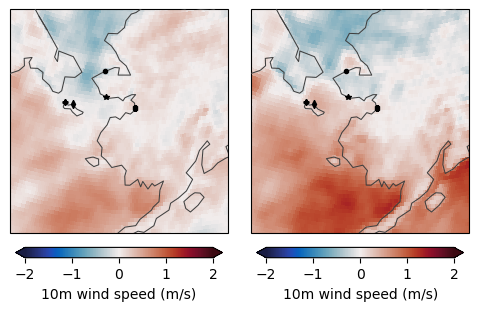

In [65]:
#### 
# create figure
fig = plt.figure(figsize=(12,8))
fout = 'figure_7_decadal_'+var_in+'_node_'+village_node+'_composites'

# Make subplots - note it's nrow x ncol x index (starting upper left)
### 2000 DIFF
ax = fig.add_subplot(2,2,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(lon1d,lat1d,diff_2000, vmin=vmin_diff, vmax=vmax_diff, cmap=cmap_diff, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
#plt.title('Mid Period - Early Period',fontsize=12)
plt.colorbar(cs, ax=ax, orientation='horizontal', label='10m wind speed ('+units+')', extend='both', pad=0.05, shrink=0.3)

# Add primary village locations and names
for name, lonv, latv, shape,size in zip(village_names_1, village_lons_1, village_lats_1, village_shapes_1,village_sizes_1):
    ax.plot(lonv, latv,marker=shape,markersize=size,linestyle='none',color='black',label=name,zorder=100,transform=ccrs.PlateCarree())

### 2050
ax = fig.add_subplot(2,2,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(lon1d,lat1d,diff_2050, vmin=vmin_diff, vmax=vmax_diff, cmap=cmap_diff, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
#plt.title('Late Period - Early Period',fontsize=12)
plt.colorbar(cs, ax=ax, orientation='horizontal', label='10m wind speed ('+units+')', extend='both', pad=0.05, shrink=0.3)

# Add primary village locations and names
for name, lonv, latv, shape,size in zip(village_names_1, village_lons_1, village_lats_1, village_shapes_1,village_sizes_1):
    ax.plot(lonv, latv,marker=shape,markersize=size,linestyle='none',color='black',label=name,zorder=100,transform=ccrs.PlateCarree())

# save figure
fig.subplots_adjust(wspace=-0.65)
#fig.subplots_adjust(hspace=0.05)
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)

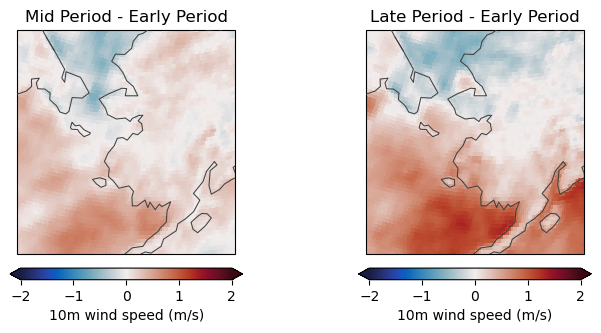

In [66]:
#### 
# create figure
fig = plt.figure(figsize=(12,8))
fout = 'figure_7_label'

# Make subplots - note it's nrow x ncol x index (starting upper left)
### 2000 DIFF
ax = fig.add_subplot(2,2,1, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(lon1d,lat1d,diff_2000, vmin=vmin_diff, vmax=vmax_diff, cmap=cmap_diff, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
plt.title('Mid Period - Early Period',fontsize=12)
plt.colorbar(cs, ax=ax, orientation='horizontal', label='10m wind speed ('+units+')', extend='both', pad=0.05, shrink=0.4)

### 2050
ax = fig.add_subplot(2,2,2, projection=ccrs.NorthPolarStereo(central_longitude=lon_avg))
cs = ax.pcolormesh(lon1d,lat1d,diff_2050, vmin=vmin_diff, vmax=vmax_diff, cmap=cmap_diff, transform=ccrs.PlateCarree())
# add features
ax.set_extent([lon_min,lon_max,lat_min,lat_max], crs=ccrs.PlateCarree())
ax.coastlines(resolution='110m', color='0.25', linewidth=0.75, zorder=10)
plt.title('Late Period - Early Period',fontsize=12)
plt.colorbar(cs, ax=ax, orientation='horizontal', label='10m wind speed ('+units+')', extend='both', pad=0.05, shrink=0.4)

# Finalize figure and save
#add title
#fig.suptitle('10m Wind Speed Decadal Composites for Pattern '+village_node,fontsize=15, y=0.92)

# save figure
fig.subplots_adjust(wspace=-0.4)
#fig.subplots_adjust(hspace=0.05)
fig = plt.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig = plt.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)